In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [86]:
df = pd.read_csv('/content/Messy_data.csv')
print(df.head())
print(df.describe(include='all'))
print(df.info())
print(df.size)

   OrderID  CustomerName     City     Product Quantity UnitPrice   OrderDate  \
0    10001   Nikhil Jain   Mumbai      Laptop      3.0  50790.72  2026-01-18   
1    10002   Simran Kaur   delhi      Monitor      1.0  10307.27  2026-01-28   
2    10003      Zoya Ali    Delhi  Headphones      5.0   2439.64  2026-02-27   
3    10004  Priya Bansal    Delhi      Tablet      4.0  20945.65  02/03/2026   
4    10005           NaN   Mumbai       Phone      4.0  15822.27  2026-02-14   

  OrderStatus CustomerAge  
0   Completed        61.0  
1     Pending        50.0  
2   Delivered        35.0  
3     Pending        66.0  
4   Delivered        34.0  
             OrderID CustomerName       City Product Quantity UnitPrice  \
count     185.000000          183        183     185      183       183   
unique           NaN           33         12      10        9       178   
top              NaN  Simran Kaur  Bengaluru   Phone      1.0   5768.41   
freq             NaN           12         33      3

In [87]:
print(df.isnull().sum())

OrderID         0
CustomerName    2
City            2
Product         0
Quantity        2
UnitPrice       2
OrderDate       2
OrderStatus     2
CustomerAge     2
dtype: int64


In [88]:
print(df.duplicated().sum())

5


In [89]:
print(df.shape)

(185, 9)


In [90]:
df.drop_duplicates(inplace=True)

In [91]:
print(df.duplicated().sum())

0


In [92]:
print(df.shape)

(180, 9)


In [93]:
#clean extra spaces and standardized text
text_column=['CustomerName ','City' ,'Product','OrderStatus']
df['CustomerName'] = df['CustomerName'].str.strip()
df['City'] = df['City'].str.strip()
df['Product'] = df['Product'].str.strip()
df['OrderStatus'] = df['OrderStatus'].str.strip()





In [94]:
text_column = ['CustomerName', 'City', 'Product', 'OrderStatus']
for col in text_column:
    df[col] = df[col].str.title()

In [95]:
df['UnitPrice']=pd.to_numeric(df['UnitPrice'],errors='coerce')

In [96]:
#outlirs
Q1=df['UnitPrice'].quantile(0.25)
Q3=df['UnitPrice'].quantile(0.75)
IQR=Q3-Q1
print(IQR)

17033.3125


In [97]:
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR
print(upper_limit)
print(lower_limit)

45034.36625
-23098.88375


In [98]:
df['Quantity']=pd.to_numeric(df['Quantity'],errors='coerce')
df['Quantity']=df['Quantity'].fillna(df['Quantity'].mean())
df['Quantity']=df['Quantity'].astype(int)

In [99]:
df['correct_UnitPrice'] = df['UnitPrice'].clip(lower=lower_limit, upper=upper_limit)
print(df[['correct_UnitPrice', 'UnitPrice']].head(30))

    correct_UnitPrice  UnitPrice
0         45034.36625   50790.72
1         10307.27000   10307.27
2          2439.64000    2439.64
3         20945.65000   20945.65
4         15822.27000   15822.27
5          5768.41000    5768.41
6          2159.37000    2159.37
7         16801.06000   16801.06
8          2651.37000    2651.37
9          2471.70000    2471.70
10        45034.36625   60309.74
11         1569.95000    1569.95
12         2529.23000    2529.23
13         2507.14000    2507.14
14        10428.70000   10428.70
15                NaN        NaN
16        17647.73000   17647.73
17                NaN        NaN
18        23732.57000   23732.57
19         5743.14000    5743.14
20        19252.30000   19252.30
21         5847.00000    5847.00
22        45034.36625  999999.00
23        16513.37000   16513.37
24         2178.24000    2178.24
25         1506.37000    1506.37
26         7055.01000    7055.01
27         1460.00000    1460.00
28        16334.59000   16334.59
29        

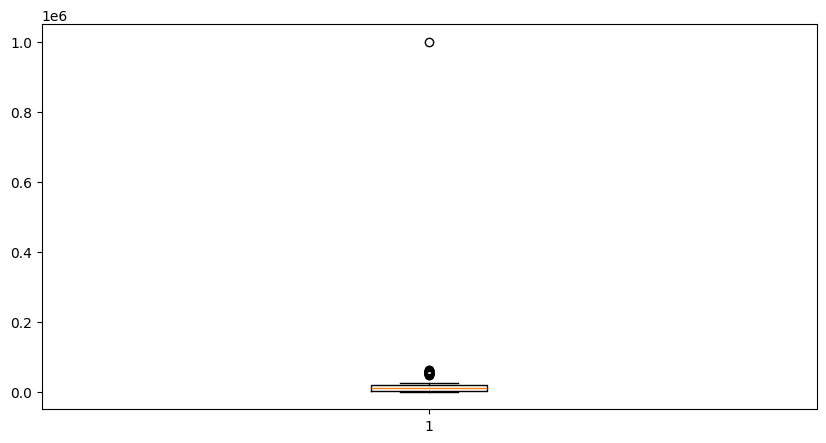

In [125]:
plt.figure(figsize=(10,5))
plt.boxplot(df['UnitPrice'].dropna())
plt.show()

In [112]:
df['Quantity']=pd.to_numeric(df['Quantity'],errors='coerce')
df['Total_Price']=df['Quantity']*df['UnitPrice']

In [110]:
#missing values
df['CustomerName']=df['CustomerName'].fillna('Unknown')
df['City']=df['City'].fillna('Unknown')
df['Product']=df['Product'].fillna('Unknown')
df['UnitPrice']=df['UnitPrice'].fillna(df['UnitPrice'].mean())
df['Quantity']=df['Quantity'].fillna(df['Quantity'].mean())

In [113]:
df.drop(columns=['correct_UnitPrice'], inplace=True, errors='ignore')

In [115]:
df['CustomerAge']=pd.to_numeric(df['CustomerAge'],errors='coerce')
df['CustomerAge']=df['CustomerAge'].fillna(df['CustomerAge'].mean())
df['CustomerAge']=df['CustomerAge'].astype(int)

In [122]:
df['OrderDate']=pd.to_datetime(df['OrderDate'],errors='coerce')
df['OrderDate']=df['OrderDate'].fillna(df['OrderDate'].mean())

In [120]:
df['OrderStatus']=df['OrderStatus'].fillna('Unknown')

In [123]:
from google.colab import files

df.to_csv('cleaned_data.csv', index=False)
files.download('cleaned_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>